In [1]:
from sklearn.ensemble import IsolationForest
print("ok")

ok


In [2]:
import json, os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
print("basic imports ok")

basic imports ok


In [3]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_score, recall_score, f1_score
print("sklearn ok")

sklearn ok


In [4]:
DATA_DIR = "../data/realAWSCloudwatch"
files = sorted(glob.glob(f"{DATA_DIR}/*.csv"))

with open("../data/labels/combined_windows.json") as f:
    windows = json.load(f)

name = os.path.basename(files[2])
df = pd.read_csv(f"{DATA_DIR}/{name}", parse_dates=["timestamp"])

wins = [(pd.to_datetime(s), pd.to_datetime(e))
        for s, e in windows.get(f"realAWSCloudwatch/{name}", [])]

label = np.zeros(len(df), dtype=int)
for s, e in wins:
    label |= ((df["timestamp"] >= s) & (df["timestamp"] <= e)).values.astype(int)
df["label"] = label

print(name, df.shape, "| windows:", len(wins), "| anomalous points:", df["label"].sum())

ec2_cpu_utilization_5f5533.csv (4032, 3) | windows: 2 | anomalous points: 402


In [5]:
W = 12                                   # previous 12 readings (about 1 hour)
v = df["value"]
prev = v.shift(1)                        # keeps the current reading out of its own baseline

df["roll_mean"] = prev.rolling(W).mean()
df["roll_std"]  = prev.rolling(W).std()
df["zscore"]    = (v - df["roll_mean"]) / df["roll_std"]
df["diff1"]     = v.diff()

df = df.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)
FEATURES = ["value", "roll_mean", "roll_std", "zscore", "diff1"]
df[FEATURES].describe()

,value,roll_mean,roll_std,zscore,diff1
count,4020.000000,4020.000000,4020.000000,4020.000000,4020.000000
mean,43.099959,43.113067,2.754663,-0.009187,-0.002986
std,4.300555,3.181725,1.245661,1.075575,5.072660
min,34.766000,37.719833,0.454928,-4.027276,-30.276000
25%,39.290500,38.535542,1.409030,-0.673558,-3.244000
50%,42.910000,43.606250,3.042799,-0.147738,-0.399000
75%,45.986000,46.092333,3.659014,0.622163,2.115000
max,68.092000,49.468525,9.356527,5.703226,22.200000


In [6]:
df["pred_z"] = (df["zscore"].abs() > 3).astype(int)
print("Baseline flags:", df["pred_z"].sum())

Baseline flags: 25


In [7]:
split = int(len(df) * 0.3)

iso = IsolationForest(n_estimators=200, random_state=42)
iso.fit(df.loc[:split, FEATURES])

df["iso_score"] = -iso.score_samples(df[FEATURES])     # higher = more unusual
thr = df["iso_score"].iloc[:split].quantile(0.995)     # threshold from the training period
df["pred_iso"] = (df["iso_score"] > thr).astype(int)
print("Isolation Forest flags:", df["pred_iso"].sum())

Isolation Forest flags: 1374


In [8]:
def evaluate(col):
    pred = df[col].values
    p = precision_score(df["label"], pred, zero_division=0)
    r = recall_score(df["label"], pred, zero_division=0)
    f = f1_score(df["label"], pred, zero_division=0)
    caught = 0
    for s, e in wins:
        m = ((df["timestamp"] >= s) & (df["timestamp"] <= e)).values
        caught += int(pred[m].sum() > 0)
    print(f"{col}: precision={p:.2f}  recall={r:.2f}  F1={f:.2f}  windows caught={caught}/{len(wins)}")

evaluate("pred_z")
evaluate("pred_iso")

pred_z: precision=0.16  recall=0.01  F1=0.02  windows caught=2/2
pred_iso: precision=0.09  recall=0.30  F1=0.13  windows caught=2/2


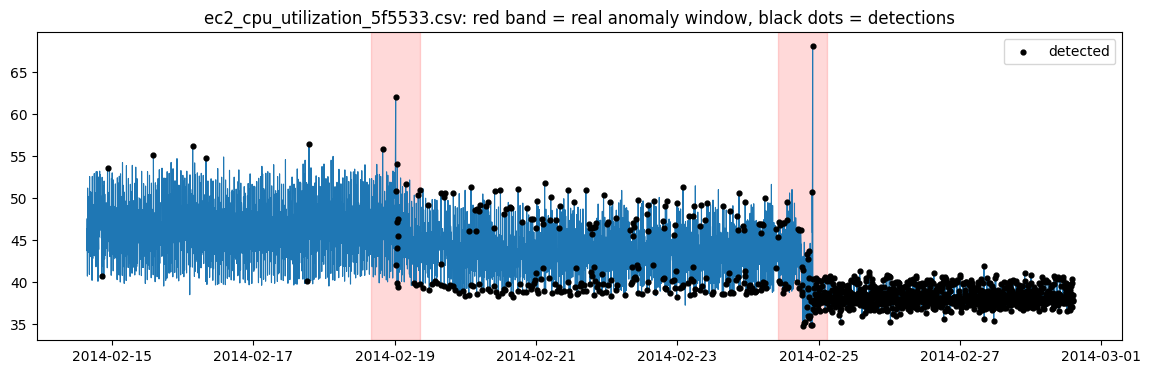

In [9]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df["timestamp"], df["value"], linewidth=0.8)
for s, e in wins:
    ax.axvspan(s, e, color="red", alpha=0.15)
flag = df[df["pred_iso"] == 1]
ax.scatter(flag["timestamp"], flag["value"], color="black", s=12, zorder=3, label="detected")
ax.legend()
ax.set_title(f"{name}: red band = real anomaly window, black dots = detections")
plt.show()

In [10]:
v = df["value"]
prev = v.shift(1)
L = 72                                   # about 6 hours of history
df["z_long"] = (v - prev.rolling(L).mean()) / prev.rolling(L).std()

df = df.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)
FEATURES2 = ["zscore", "z_long", "diff1"]
print(df.shape)

(3948, 11)


In [11]:
split = int(len(df) * 0.3)

iso2 = IsolationForest(n_estimators=200, random_state=42)
iso2.fit(df.loc[:split, FEATURES2])

df["iso2_score"] = -iso2.score_samples(df[FEATURES2])
thr2 = df["iso2_score"].iloc[:split].quantile(0.995)
df["pred_iso2"] = (df["iso2_score"] > thr2).astype(int)
print("Flags:", df["pred_iso2"].sum())

Flags: 46


In [12]:
def alert_report(col):
    pred = df[col].values
    days = (df["timestamp"].iloc[-1] - df["timestamp"].iloc[0]).total_seconds() / 86400
    outside = int(((pred == 1) & (df["label"].values == 0)).sum())
    print(f"{col}: flags outside windows = {outside} ({outside/days:.1f} per day)")
    for i, (s, e) in enumerate(wins):
        m = ((df["timestamp"] >= s) & (df["timestamp"] <= e)).values
        hits = df.loc[m & (pred == 1), "timestamp"]
        if len(hits):
            print(f"  window {i+1}: first detection {hits.iloc[0] - s} after window start")
        else:
            print(f"  window {i+1}: missed")

evaluate("pred_z");     alert_report("pred_z")
evaluate("pred_iso");   alert_report("pred_iso")
evaluate("pred_iso2");  alert_report("pred_iso2")


pred_z: precision=0.16  recall=0.01  F1=0.02  windows caught=2/2
pred_z: flags outside windows = 21 (1.5 per day)
  window 1: first detection 0 days 08:20:00 after window start
  window 2: first detection 0 days 08:20:00 after window start
pred_iso: precision=0.09  recall=0.30  F1=0.13  windows caught=2/2
pred_iso: flags outside windows = 1254 (91.5 per day)
  window 1: first detection 0 days 03:55:00 after window start
  window 2: first detection 0 days 00:05:00 after window start
pred_iso2: precision=0.09  recall=0.01  F1=0.02  windows caught=2/2
pred_iso2: flags outside windows = 42 (3.1 per day)
  window 1: first detection 0 days 03:55:00 after window start
  window 2: first detection 0 days 11:30:00 after window start


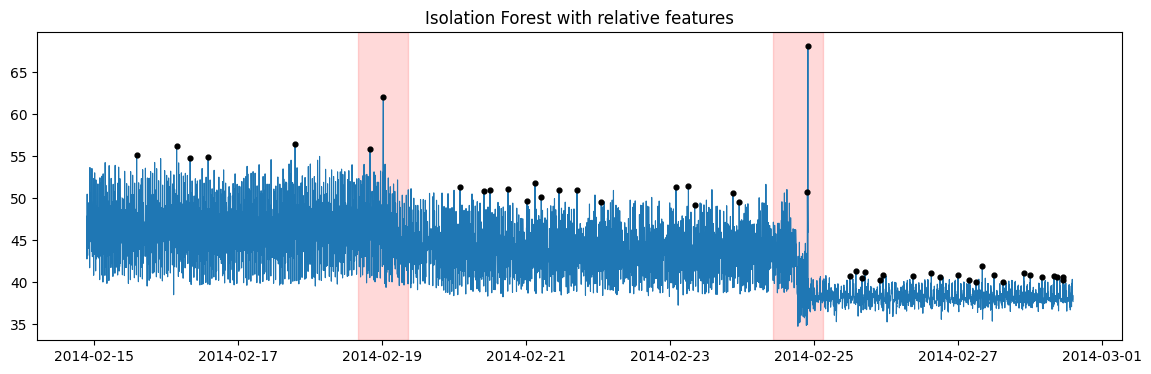

In [13]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df["timestamp"], df["value"], linewidth=0.8)
for s, e in wins:
    ax.axvspan(s, e, color="red", alpha=0.15)
flag = df[df["pred_iso2"] == 1]
ax.scatter(flag["timestamp"], flag["value"], color="black", s=12, zorder=3)
ax.set_title("Isolation Forest with relative features")
plt.show()

In [14]:
days = (df["timestamp"].iloc[-1] - df["timestamp"].iloc[0]).total_seconds() / 86400

for q in [0.99, 0.995, 0.998, 0.999, 0.9995]:
    t = df["iso2_score"].iloc[:split].quantile(q)
    pred = (df["iso2_score"] > t).astype(int).values
    outside = int(((pred == 1) & (df["label"].values == 0)).sum())
    caught = sum(
        int(pred[((df["timestamp"] >= s) & (df["timestamp"] <= e)).values].sum() > 0)
        for s, e in wins
    )
    print(f"q={q}: false alarms/day={outside/days:.1f}  windows caught={caught}/{len(wins)}")

q=0.99: false alarms/day=7.7  windows caught=2/2
q=0.995: false alarms/day=3.1  windows caught=2/2
q=0.998: false alarms/day=0.7  windows caught=2/2
q=0.999: false alarms/day=0.1  windows caught=2/2
q=0.9995: false alarms/day=0.1  windows caught=1/2


In [15]:
def run_file(path, q=0.999, W=12, L=72, train_frac=0.3):
    name = os.path.basename(path)
    d = pd.read_csv(path, parse_dates=["timestamp"])
    ws = [(pd.to_datetime(s), pd.to_datetime(e))
          for s, e in windows.get(f"realAWSCloudwatch/{name}", [])]

    lab = np.zeros(len(d), dtype=int)
    for s, e in ws:
        lab |= ((d["timestamp"] >= s) & (d["timestamp"] <= e)).values.astype(int)
    d["label"] = lab

    v = d["value"]; prev = v.shift(1)
    d["zscore"] = (v - prev.rolling(W).mean()) / prev.rolling(W).std()
    d["z_long"] = (v - prev.rolling(L).mean()) / prev.rolling(L).std()
    d["diff1"]  = v.diff()
    d = d.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)

    feats = ["zscore", "z_long", "diff1"]
    split = int(len(d) * train_frac)
    train = d.iloc[:split]
    train = train[train["label"] == 0]         

    iso = IsolationForest(n_estimators=200, random_state=42).fit(train[feats])
    thr = np.quantile(-iso.score_samples(train[feats]), q)
    d["pred_iso"] = ((-iso.score_samples(d[feats])) > thr).astype(int)
    d["pred_z"]   = (d["zscore"].abs() > 3).astype(int)

    days = (d["timestamp"].iloc[-1] - d["timestamp"].iloc[0]).total_seconds() / 86400
    out = {"file": name, "windows": len(ws)}
    for col in ["pred_z", "pred_iso"]:
        pred = d[col].values
        outside = int(((pred == 1) & (d["label"].values == 0)).sum())
        caught = sum(
            int(pred[((d["timestamp"] >= s) & (d["timestamp"] <= e)).values].sum() > 0)
            for s, e in ws
        )
        out[f"{col}_caught"] = caught
        out[f"{col}_fa_per_day"] = round(outside / days, 2)
    return out

rows = [run_file(f, q=0.999) for f in files]
res = pd.DataFrame(rows)
display(res)

print("\nTOTAL windows:", res["windows"].sum())
print("z-score : caught", res["pred_z_caught"].sum(), "| avg false alarms/day", round(res["pred_z_fa_per_day"].mean(), 2))
print("iso     : caught", res["pred_iso_caught"].sum(), "| avg false alarms/day", round(res["pred_iso_fa_per_day"].mean(), 2))

,file,windows,pred_z_caught,pred_z_fa_per_day,pred_iso_caught,pred_iso_fa_per_day
0,ec2_cpu_utilization_24ae8d.csv,2,2,5.75,0,0.51
1,ec2_cpu_utilization_53ea38.csv,2,2,3.86,1,0.44
2,ec2_cpu_utilization_5f5533.csv,2,2,1.53,2,0.65
3,ec2_cpu_utilization_77c1ca.csv,1,1,13.02,0,0.29
4,ec2_cpu_utilization_825cc2.csv,1,1,5.38,1,0.22
5,ec2_cpu_utilization_ac20cd.csv,1,1,4.72,0,0.15
6,ec2_cpu_utilization_c6585a.csv,0,0,2.26,0,0.44
7,ec2_cpu_utilization_fe7f93.csv,3,3,16.37,0,0.22
8,ec2_disk_write_bytes_1ef3de.csv,1,1,6.11,0,0.81
9,ec2_disk_write_bytes_c0d644.csv,3,2,11.31,0,0.29



TOTAL windows: 30
z-score : caught 29 | avg false alarms/day 7.65
iso     : caught 11 | avg false alarms/day 0.49


In [16]:
def prepare(path, W=12, L=72, train_frac=0.3):
    name = os.path.basename(path)
    d = pd.read_csv(path, parse_dates=["timestamp"])
    ws = [(pd.to_datetime(s), pd.to_datetime(e))
          for s, e in windows.get(f"realAWSCloudwatch/{name}", [])]

    lab = np.zeros(len(d), dtype=int)
    for s, e in ws:
        lab |= ((d["timestamp"] >= s) & (d["timestamp"] <= e)).values.astype(int)
    d["label"] = lab

    v = d["value"]; prev = v.shift(1)
    d["zscore"] = (v - prev.rolling(W).mean()) / prev.rolling(W).std()
    d["z_long"] = (v - prev.rolling(L).mean()) / prev.rolling(L).std()
    d["diff1"]  = v.diff()
    d = d.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)

    feats = ["zscore", "z_long", "diff1"]
    split = int(len(d) * train_frac)
    train = d.iloc[:split]
    train = train[train["label"] == 0]

    iso = IsolationForest(n_estimators=200, random_state=42).fit(train[feats])
    d["iso_score"] = -iso.score_samples(d[feats])
    days = (d["timestamp"].iloc[-1] - d["timestamp"].iloc[0]).total_seconds() / 86400
    return {"name": name, "d": d, "ws": ws,
            "train_scores": d.loc[train.index, "iso_score"].values, "days": days}

def evaluate_cfg(P, iso_q=None, z_thr=None):
    d = P["d"]
    if iso_q is not None:
        pred = (d["iso_score"] > np.quantile(P["train_scores"], iso_q)).astype(int).values
    else:
        pred = (d["zscore"].abs() > z_thr).astype(int).values
    outside = int(((pred == 1) & (d["label"].values == 0)).sum())
    caught = sum(
        int(pred[((d["timestamp"] >= s) & (d["timestamp"] <= e)).values].sum() > 0)
        for s, e in P["ws"]
    )
    return caught, outside / P["days"]

prepped = [prepare(f) for f in files]        # takes about 35 seconds, once
total = sum(len(P["ws"]) for P in prepped)

def summarize(label, **kw):
    res = [evaluate_cfg(P, **kw) for P in prepped]
    caught = sum(r[0] for r in res)
    fa = np.mean([r[1] for r in res])
    print(f"{label}: caught {caught}/{total} | avg false alarms/day {fa:.2f}")

for q in [0.95, 0.98, 0.99, 0.995, 0.998, 0.999]:
    summarize(f"iso q={q}", iso_q=q)
print()
for z in [3, 4, 5, 6, 8]:
    summarize(f"z > {z}", z_thr=z)

iso q=0.95: caught 28/30 | avg false alarms/day 22.60
iso q=0.98: caught 27/30 | avg false alarms/day 10.38
iso q=0.99: caught 22/30 | avg false alarms/day 6.30
iso q=0.995: caught 20/30 | avg false alarms/day 1.66
iso q=0.998: caught 17/30 | avg false alarms/day 0.83
iso q=0.999: caught 11/30 | avg false alarms/day 0.48

z > 3: caught 29/30 | avg false alarms/day 7.65
z > 4: caught 27/30 | avg false alarms/day 4.29
z > 5: caught 27/30 | avg false alarms/day 3.30
z > 6: caught 23/30 | avg false alarms/day 2.88
z > 8: caught 22/30 | avg false alarms/day 2.43


In [17]:
def get_pred(P, iso_q=None, z_thr=None):
    d = P["d"]
    if iso_q is not None:
        return (d["iso_score"] > np.quantile(P["train_scores"], iso_q)).astype(int).values
    return (d["zscore"].abs() > z_thr).astype(int).values

def incident_eval(P, pred, gap_minutes=60):
    d = P["d"]
    ts = d["timestamp"].values
    labels = d["label"].values
    idx = np.where(pred == 1)[0]

    groups = []
    for i in idx:
        if groups and (ts[i] - ts[groups[-1][-1]]) / np.timedelta64(1, "m") <= gap_minutes:
            groups[-1].append(i)
        else:
            groups.append([i])

    false_inc = sum(1 for g in groups if labels[g].sum() == 0)
    raw_false = int(((pred == 1) & (labels == 0)).sum())
    caught = sum(
        int(pred[((d["timestamp"] >= s) & (d["timestamp"] <= e)).values].sum() > 0)
        for s, e in P["ws"]
    )
    return caught, raw_false / P["days"], false_inc / P["days"]

def summarize_inc(label, gap=60, **kw):
    res = [incident_eval(P, get_pred(P, **kw), gap) for P in prepped]
    caught = sum(r[0] for r in res)
    raw = np.mean([r[1] for r in res])
    inc = np.mean([r[2] for r in res])
    print(f"{label}: caught {caught}/{total} | raw false alarms/day {raw:.2f} -> false incidents/day {inc:.2f}")

summarize_inc("z > 3", z_thr=3)
summarize_inc("z > 4", z_thr=4)
summarize_inc("z > 5", z_thr=5)
summarize_inc("z > 6", z_thr=6)
summarize_inc("iso q=0.99", iso_q=0.99)
summarize_inc("iso q=0.995", iso_q=0.995)

z > 3: caught 29/30 | raw false alarms/day 7.65 -> false incidents/day 4.94
z > 4: caught 27/30 | raw false alarms/day 4.29 -> false incidents/day 3.08
z > 5: caught 27/30 | raw false alarms/day 3.30 -> false incidents/day 2.38
z > 6: caught 23/30 | raw false alarms/day 2.88 -> false incidents/day 2.09
iso q=0.99: caught 22/30 | raw false alarms/day 6.30 -> false incidents/day 2.13
iso q=0.995: caught 20/30 | raw false alarms/day 1.66 -> false incidents/day 1.37


In [18]:
def with_persistence(pred, k):
    if k == 1:
        return pred
    return (pd.Series(pred).rolling(k).min().fillna(0) == 1).astype(int).values

for z in [3, 4, 5]:
    for k in [1, 2, 3]:
        res = [incident_eval(P, with_persistence(get_pred(P, z_thr=z), k), 60) for P in prepped]
        caught = sum(r[0] for r in res)
        inc = np.mean([r[2] for r in res])
        print(f"z>{z}, need {k} in a row: caught {caught}/{total} | false incidents/day {inc:.2f}")

z>3, need 1 in a row: caught 29/30 | false incidents/day 4.94
z>3, need 2 in a row: caught 16/30 | false incidents/day 1.10
z>3, need 3 in a row: caught 5/30 | false incidents/day 0.20
z>4, need 1 in a row: caught 27/30 | false incidents/day 3.08
z>4, need 2 in a row: caught 12/30 | false incidents/day 0.71
z>4, need 3 in a row: caught 3/30 | false incidents/day 0.08
z>5, need 1 in a row: caught 27/30 | false incidents/day 2.38
z>5, need 2 in a row: caught 12/30 | false incidents/day 0.54
z>5, need 3 in a row: caught 2/30 | false incidents/day 0.07


In [19]:
inside, outside = [], []
for P in prepped:
    d = P["d"]
    flagged = d[d["zscore"].abs() > 5]
    inside += flagged.loc[flagged["label"] == 1, "zscore"].abs().tolist()
    outside += flagged.loc[flagged["label"] == 0, "zscore"].abs().tolist()

print("flags inside windows :", len(inside), "| median |z|:", round(float(np.median(inside)), 1))
print("flags outside windows:", len(outside), "| median |z|:", round(float(np.median(outside)), 1))
print("inside, percentiles 25/50/75:", np.percentile(inside, [25, 50, 75]).round(1))
print("outside, percentiles 25/50/75:", np.percentile(outside, [25, 50, 75]).round(1))

flags inside windows : 118 | median |z|: 14.4
flags outside windows: 768 | median |z|: 17.6
inside, percentiles 25/50/75: [ 8.4 14.4 67.8]
outside, percentiles 25/50/75: [ 8.2 17.6 60.6]
